1.1 各国地震死亡人数统计
提取 Country（国家）和 Deaths（死亡人数）两列，使用 groupby() 按国家分组，再用 sum() 计算各国死亡人数总和。最后计算全球记录中的死亡人数总和，并按死亡人数降序排列，输出前 20 名国家。
1.2 每年震级大于 3.0 的地震数量
筛选 Mag > 3.0 的地震记录，按照 Year（年份）分组，使用 size() 统计每年的地震数量，再用 matplotlib 绘制时间序列折线图。最后观察地震记录数量的变化趋势，并讨论监测技术和历史记录完整性对结果的影响。
1.3 各国地震次数及最大地震信息
编写一个函数，输入国家名称后，统计该国的地震记录总数，并根据 Mag 找到震级最大的地震，提取其发生日期和地点。然后使用 for 循环遍历所有国家，将结果整理成表格，按照地震次数降序排列。

In [47]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline

met = pd.read_csv("earthquakes-2026-10-14_21-39-07_+0800(1).tsv", sep="\t") #去掉了 ../因为我们TSV文件已经放进了Notebook当前所在的文件夹
print(met.shape)                                                            #表格的行列数
print(met.columns.tolist())                                                 #表格的表头                                                       
met1=met[["Country", "Deaths"]]                                             #把国家和死亡数提取出来
country_deaths=met1.groupby("Country")["Deaths"].sum()                      #把相同国家的死亡人数划分到一起
print("全球地震记录中的死亡人数总和：", country_deaths.sum())                #打印出全球地震记录中的死亡人数总和
country_deaths = country_deaths.sort_values(ascending=False)                #按照死亡人数降序排列
print("死亡人数最多的20个国家：",country_deaths.head(20))                    #这个数据把中国跟台湾分开算了，坚持一个中国原则

<class 'pandas.DataFrame'>
RangeIndex: 6698 entries, 0 to 6697
Data columns (total 49 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Search Parameters                   1 non-null      str    
 1   Id                                  6697 non-null   float64
 2   Year                                6697 non-null   float64
 3   Mo                                  6293 non-null   float64
 4   Dy                                  6122 non-null   float64
 5   Hr                                  4580 non-null   float64
 6   Mn                                  4357 non-null   float64
 7   Sec                                 3864 non-null   float64
 8   Tsu                                 2124 non-null   float64
 9   Vol                                 82 non-null     float64
 10  Country                             6697 non-null   str    
 11  Area                                335 non-null    st

震级大于3.0的地震记录数量： 4902
Year
-2150.0     1
-2000.0     2
-1610.0     1
-1566.0     1
-1450.0     1
           ..
 2022.0    51
 2023.0    46
 2024.0    36
 2025.0    43
 2026.0    19
Length: 970, dtype: int64


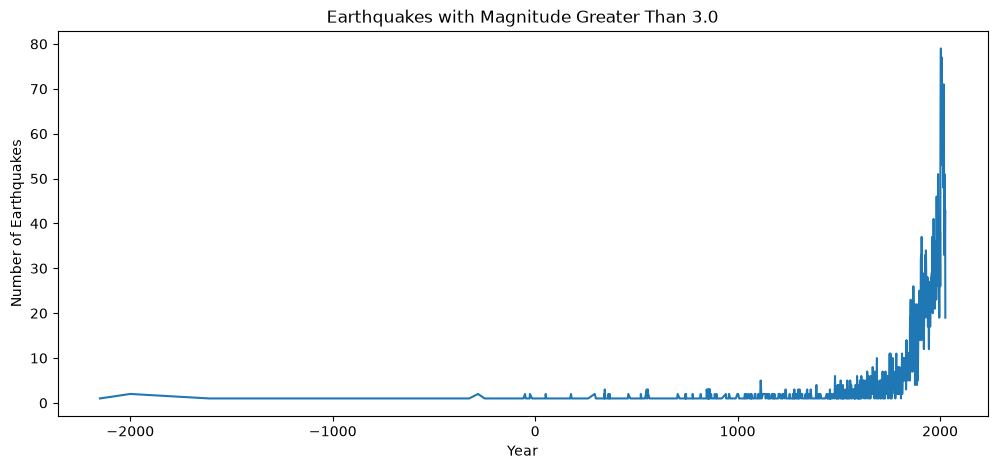

In [46]:
met2=met[["Year", "Mag"]]                           #把年份和地震数提取出来
year_counts = met2.groupby("Year").size()           #按相同年份统计地震记录数量
met2 =  met2[met2["Mag"] > 3.0]                     #筛选震级大于3.0的地震数量
print("震级大于3.0的地震记录数量：", len(met2))     #输出
print(year_counts)
plt.figure(figsize=(12, 5))                         #设置图表大小
plt.plot(year_counts.index, year_counts.values)     #画折线图
plt.xlabel("Year")                                  #设置横坐标“年份”
plt.ylabel("Number of Earthquakes")                 #设置总坐标“地震数量”
plt.title("Earthquakes with Magnitude Greater Than 3.0")          #设置标题
plt.show()

In [55]:
#复制一份数据
met3 = met.copy()  
#定义函数
def get_country_info(country):
   # 找出这个国家的所有地震记录
    data = met3[met3["Country"] == country]
    count = len(data)
    #按照降序排列
    data = data.sort_values("Mag", ascending=False)
    #找出最大的那一次地震
    biggest = data.iloc[0]
    #确定最大那次地震的年月日
    year = biggest["Year"]
    month = biggest["Mo"]
    day = biggest["Dy"]
    #确定年的缺失值
    if pd.isna(year):
        date = "Unknown"
    #确定是公元前还是公元后
    else:
        year = int(year)
        if year < 0:
            date = str(abs(year)) + " B.C."
        else:
            date = str(year) + " A.D."
        #检测非缺失值
        if pd.notna(month):
            date = date + "-" + str(int(month))
            if pd.notna(day):
                date = date + "-" + str(int(day))
    #确定地震的范围
    location = biggest["Location Name"]
    if pd.isna(location) or str(location).strip() == "":
        location = biggest["Area"]
    if pd.isna(location) or str(location).strip() == "":
        location = biggest["Region"]
    if pd.isna(location) or str(location).strip() == "":
        location = "Unknown"
    return count, date, location
# 找出所有国家的名称；dropna()删除缺失值；unique()只保留一次每个国家名字
countries = met3["Country"].dropna().unique()
# 创建出一个空列表，用来保存最终结果
results = []
# 逐个国家进行统计
for country in countries:
    # 调用函数，获取这个国家的三个结果
    count, date, location = get_country_info(country)
    # 把结果保存到列表中
    results.append([country, count, date, location])
# 把结果整理成表格
results = pd.DataFrame(results,columns=["Country", "CountEq", "LargestEqDate", "LargestEqLocation"])
# 按地震记录数量从大到小排序
results = results.sort_values("CountEq", ascending=False)
# 显示最终表格
display(results)

,Country,CountEq,LargestEqDate,LargestEqLocation
14,CHINA,626,1668 A.D.-7-25,CHINA: SHANDONG PROVINCE
33,JAPAN,429,2011 A.D.-3-11,JAPAN: HONSHU
73,INDONESIA,427,2004 A.D.-12-26,INDONESIA: SUMATRA: ACEH: OFF WEST COAST
7,IRAN,385,856 A.D.-12-22,"IRAN: DAMGHAN, QUMIS"
9,TURKEY,359,1939 A.D.-12-26,TURKEY: ERZINCAN
...,...,...,...,...
154,BURUNDI,1,2004 A.D.-2-24,BURUNDI: RUYAGA
158,CZECH REPUBLIC,1,2008 A.D.-11-22,CZECH REPUBLIC: KARVINA
159,MADAGASCAR,1,2017 A.D.-1-11,MADAGASCAR: ANTSIRABE
160,ZAMBIA,1,2017 A.D.-2-24,ZAMBIA: KAPUTA


分析深圳宝安机场 1998—2022 年的气温变化
首先，使用 pandas 读取 Baoan_Weather_1998_2022.csv 文件，参考 NOAA ISD 数据格式说明，识别观测时间、气温和数据质量标记等字段，并筛选有效的小时气温数据。
接着，将观测时间整理为日期格式，用str.split()将温度与质量码分开，然后用isin()检验质量码，根据手册的计算方式将温度转换成摄氏度，随后按月份分组，计算每个月的平均气温。最后，绘制月平均气温随时间变化的折线图，观察 1998—2022 年的气温变化趋势，发现其并没有显著的长期升温或者长期降温的趋势

C:\Users\28223\AppData\Local\Temp\ipykernel_6744\2001602611.py:2: DtypeWarning: Columns (0: CALL_SIGN, 1: AA3, 2: AG1, 3: AJ1, 4: AW1, 5: AZ1, 6: CALL_SIGN.1, 7: GA5, 8: GE1, 9: HL1, 10: IA2, 11: KA2, 12: ME1, 13: MW3, 14: OA1, 15: OD1, 16: OD2, 17: SA1, 18: UA1, 19: UG1) have mixed types. Specify dtype option on import or set low_memory=False.
  date = pd.read_csv("Baoan_Weather_1998_2022.csv")


['STATION', 'DATE', 'SOURCE', 'REPORT_TYPE', 'CALL_SIGN', 'QUALITY_CONTROL', 'AA1', 'AA2', 'AA3', 'AG1', 'AJ1', 'AW1', 'AY1', 'AY2', 'AZ1', 'CALL_SIGN.1', 'CIG', 'DEW', 'ED1', 'EQD', 'GA1', 'GA2', 'GA3', 'GA4', 'GA5', 'GE1', 'GF1', 'HL1', 'IA1', 'IA2', 'KA1', 'KA2', 'MA1', 'MD1', 'ME1', 'MW1', 'MW2', 'MW3', 'OA1', 'OC1', 'OD1', 'OD2', 'QUALITY_CONTROL.1', 'REM', 'REPORT_TYPE.1', 'SA1', 'SLP', 'SOURCE.1', 'TMP', 'UA1', 'UG1', 'VIS', 'WG1', 'WND']
(235674, 54)
DATE
1998-01-01    15.233447
1998-02-01    16.875304
1998-03-01    19.971246
1998-04-01    25.228365
1998-05-01    27.098454
Freq: MS, Name: temperature, dtype: float64


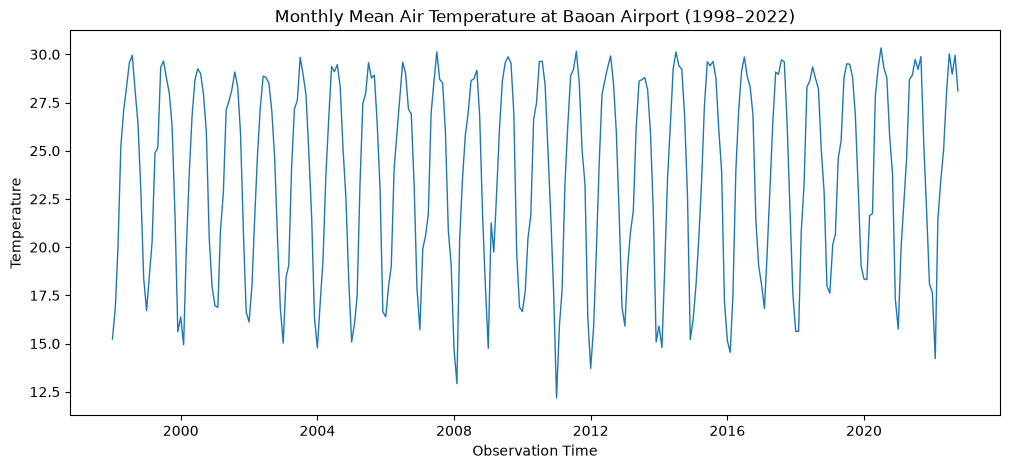

In [110]:
import pandas as pd
date = pd.read_csv("Baoan_Weather_1998_2022.csv")
print(met.columns.tolist()) 
#查看表格有多少行、多少列
print(date.shape)
date1=date[["DATE","TMP"]]#把时间和温度提取出来
date1.head()
date1["DATE"] = pd.to_datetime(date1["DATE"], errors="coerce")#将数据转换为时间类型
tmp = date1["TMP"].str.split(",", expand=True)#将温度与质量码分开
date1["temperature"] = pd.to_numeric(tmp[0], errors="coerce")#将第一列的温度数据提取出来
date1["quality"] = tmp[1].str.strip()#对质量码处理
date1 = date1.dropna(subset=["DATE", "temperature"])#删除缺失值
date1 = date1[date1["temperature"] != 9999]#将能用的温度数值提取出来
date1 = date1[date1["quality"].isin(["1", "5"])]#检验质量码，保留符合要求的
date1["temperature"] = date1["temperature"] / 10#处理温度数据，变成摄氏度
temperature = date1.groupby("DATE")["temperature"].mean()#按照日期分组
hourly = temperature.resample("h").mean()#求每小时平均空气温度
monthly = hourly.resample("MS").mean()#求每月平均空气温度
print(monthly.head())
plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly.values, linewidth=1)
plt.title("Monthly Mean Air Temperature at Baoan Airport (1998–2022)")
plt.xlabel("Observation Time")
plt.ylabel("Temperature")
plt.show()

3.1 最大风速排名前 10 的风暴
先将 WMO_WIND（风速）转换为数值，再使用 groupby() 按 SID（风暴编号）分组，通过 max() 获取每场风暴的最大风速。使用 sort_values() 从大到小排序，再用 head(10) 取出前 10 场风暴，匹配其名称，并检查排名末位的并列情况。
3.2 最大的 20 个风速记录
按照 WMO_WIND 对全部观测记录进行降序排列，使用 head(20) 提取风速最大的 20 条记录，输出名称、时间和风速。同一场风暴可能包含多条高风速记录，因此另外按 SID 分组，列出 20 场不同风暴的最大风速，区分两种统计方式。
3.3 各海盆的观测记录数
提取 BASIN（海盆）列，使用 value_counts() 统计各海盆的观测记录数。读取数据时保留北大西洋的代码 NA，避免将其识别为缺失值，造成统计遗漏。
3.4 全球观测位置的六边形密度图
提取 LON（经度）和 LAT（纬度），使用 matplotlib 的 hexbin() 绘制六边形密度图。以经度为横轴、纬度为纵轴，通过颜色表示各六边形内的观测记录数，并使用对数色阶展示不同区域的密度差异。
3.5 2018 年山竹台风的移动路径
先筛选 NAME 为 MANGKHUT 的记录，再保留 SEASON 为 2018 的数据。按照 ISO_TIME 排序，使用 plot() 将各时刻的经纬度位置依次连接，展示山竹台风的移动路径。
3.6 筛选指定年份和海盆的数据
筛选 ISO_TIME 不早于 1970 年 1 月 1 日的记录，再使用 isin() 保留西北太平洋（WP）和东北太平洋（EP）海盆的数据。将筛选结果保存为新的数据表，用于后续分析。
3.7 每天的观测记录数
使用 set_index() 将时间设为索引，通过 resample('D').size() 统计每天的观测记录数。使用 date_range() 创建连续日期，再通过 reindex() 将数据覆盖期内没有记录的日期补为 0，最后绘制日记录数时间序列图。
3.8 日记录数的气候平均值
利用 dayofyear 获取每个日期在一年中的日序，将不同年份相同日序的记录数通过 groupby() 分组，再使用 mean() 计算多年平均值。绘制气候平均值随日序变化的曲线，观察记录数的季节性变化。
3.9 每日记录数的异常值
使用 map() 为每个日期匹配对应日序的气候平均值，再用当天实际记录数减去该平均值，得到每日异常值。绘制异常值时间序列图，并添加零值参考线，展示记录数高于或低于气候平均水平的情况。
3.10 年度平均异常值及突出年份
使用 resample('YS').mean() 将每日异常值转换为年度平均异常值，排除数据不完整的 2022 年后绘制柱状图。通过排序找出正、负异常最大的年份，结果显示 1992、1994 年的观测记录数偏多，2010 年偏少。

In [ ]:
df = pd.read_csv('ibtracs.ALL.list.v04r00.csv',
                 usecols=range(17),#只读取前17列
                 skiprows=[1, 2], #跳过第二行的单位说明
                 parse_dates=['ISO_TIME'],#将时间列转换成日期时间
                 na_values=['NOT_NAMED', 'NAME'],# 将风速转换成数值，无法转换的内容设为缺失值
                 keep_default_na=False,)# 保留 NA：它是北大西洋的代码# 将风速转换成数值，无法转换的内容设为缺失值
df.head()

#同一场风暴有多条记录，所以先按 SID 分组，取每场风暴的最大风速。风速单位为节
# 把风速这一列变成数字遇到空白等无法转换的内容，就设为缺失值
df['WMO_WIND'] = pd.to_numeric(df['WMO_WIND'], errors='coerce')
# 按风暴编号分组，找出每场风暴的最大风速
max_wind = df.groupby('SID')['WMO_WIND'].max()
# 从大到小排序
max_wind = max_wind.sort_values(ascending=False)
# 取前10场风暴
top10 = max_wind.head(10)
print(top10)
# 找出每场风暴的名字
names = df.groupby('SID')['NAME'].first()
# 将前10场风暴的名字和最大风速放在一个表里
answer = pd.DataFrame()
answer['NAME'] = names.loc[top10.index]
answer['WMO_WIND'] = top10
print(answer)

# 按风速从大到小排序
sorted_df = df.sort_values('WMO_WIND', ascending=False)
# 取前20行
top20 = sorted_df.head(20)
# 显示名称、时间和风速
print(top20[['NAME', 'ISO_TIME', 'WMO_WIND']])

# 统计每种海盆代码出现了多少次value_counts()
basin_counts = df['BASIN'].value_counts()
print(basin_counts)

# 横轴是经度，纵轴是纬度
# 颜色表示每个六边形内的记录数
plt.figure(figsize=(10, 5))
plt.hexbin(df['LON'],df['LAT'],gridsize=60,mincnt=1,bins='log')
plt.colorbar(label='Number of records (log scale)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Global tropical cyclone locations')
plt.show()

# 先找名字为 MANGKHUT 的风暴
mangkhut = df[df['NAME'] == 'MANGKHUT']
# 再找2018年的记录
mangkhut = mangkhut[mangkhut['SEASON'] == 2018]
# 按时间先后排序
mangkhut = mangkhut.sort_values('ISO_TIME')
# 画路径
plt.figure(figsize=(10, 5))
plt.plot(mangkhut['LON'], mangkhut['LAT'], '.-')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Typhoon Mangkhut in 2018')
plt.grid()
plt.show()

# 第一步：保留1970年及以后的记录
data = df[df['ISO_TIME'] >= '1970-01-01']
# 第二步：判断海盆是不是 WP 或 EP
condition = data['BASIN'].isin(['WP', 'EP'])
# 第三步：保留符合条件的记录
data = data[condition].copy()
print('筛选后的记录数：', len(data))

# 把时间设为索引，方便按天统计
data = data.set_index('ISO_TIME')
# D 表示按天，size() 表示统计记录条数
daily_counts = data.resample('D').size()
# 创建从1970年1月1日到文件截止日的所有日期
last_day = df['ISO_TIME'].max().normalize()
all_days = pd.date_range('1970-01-01', last_day)
# 补齐日期，没有记录的日子填0
daily_counts = daily_counts.reindex(all_days, fill_value=0)
print(daily_counts.head())
# 画图
plt.figure(figsize=(15, 5))
plt.plot(daily_counts.index, daily_counts.values)
plt.xlabel('Year')
plt.ylabel('Records per day')
plt.title('Daily record counts: WP and EP')
plt.show()

# 建立一个表格，保存每日记录数
daily = pd.DataFrame()
daily['count'] = daily_counts
# 添加“一年中的第几天”
daily['dayofyear'] = daily.index.dayofyear
# 按日序分组，计算多年平均值
climatology = daily.groupby('dayofyear')['count'].mean()
print(climatology.head())
# 画图
plt.figure(figsize=(10, 4))
plt.plot(climatology.index, climatology.values)
plt.xlabel('Day of year')
plt.ylabel('Mean records per day')
plt.title('Climatology of daily record counts')
plt.show()

# 为每一天找到对应的气候平均值
daily['average'] = daily['dayofyear'].map(climatology)
# 实际记录数减去气候平均值
daily['anomaly'] = daily['count'] - daily['average']
print(daily.head())
# 画图
plt.figure(figsize=(12, 4))
plt.plot(daily.index, daily['anomaly'])
# 画一条0值参考线
plt.axhline(0, color='black')
plt.xlabel('Year')
plt.ylabel('Daily anomaly')
plt.title('Daily record-count anomalies')
plt.show()

# 对每天的异常值按年求平均
# YS 表示按年分组，用年初作为时间标签
annual = daily['anomaly'].resample('YS').mean()
# 排除不完整的2022年
annual = annual[annual.index.year < 2022]
# 画图
plt.figure(figsize=(12, 4))
plt.bar(annual.index.year, annual.values)
plt.axhline(0, color='black')
plt.xlabel('Year')
plt.ylabel('Mean daily anomaly')
plt.title('Annual mean anomalies: WP and EP, 1970–2021')
plt.show()
# 从大到小排序，找出记录偏多的5年
high_years = annual.sort_values(ascending=False)
print('记录偏多的5年：')
print(high_years.head(5))
# 从小到大排序，找出记录偏少的5年
low_years = annual.sort_values()
print('记录偏少的5年：')
print(low_years.head(5))

In [ ]:
本次分析使用 Burns 气象站 1908—1920 年的日气象数据。首先处理缺失值和质量检查未通过的数值，并完成气温、降水量的单位换算。对于标记为“缺测但推定为零”的降水记录，采用保守处理，将其设为缺失值。

气温时间序列呈现明显的季节变化，夏季较高，冬季较低。清理后，有效记录中日最高气温的平均值为 14.82°C，日最低气温的平均值为 -0.56°C，两者的相关系数约为 0.89，说明它们具有较强的正相关关系。

降水量和降雪量的中位数均为 0，但最大值分别达到 61 mm 和 305 mm，说明多数有效记录中的降水、降雪较少，少数记录的数值较大。积雪深度仅有 807 条有效记录，缺失较多。

['STATION', 'DATE', 'LATITUDE', 'LONGITUDE', 'ELEVATION', 'NAME', 'PRCP', 'PRCP_ATTRIBUTES', 'SNOW', 'SNOW_ATTRIBUTES', 'SNWD', 'SNWD_ATTRIBUTES', 'TMAX', 'TMAX_ATTRIBUTES', 'TMIN', 'TMIN_ATTRIBUTES', 'TOBS', 'TOBS_ATTRIBUTES']
重复日期数量： 0
清理后的缺失值数量：
DATE       0
PRCP    1310
SNOW    1187
SNWD    2424
TMAX     467
TMIN     517
TOBS     888
dtype: int64
原文件中没有记录的日期数： 1273


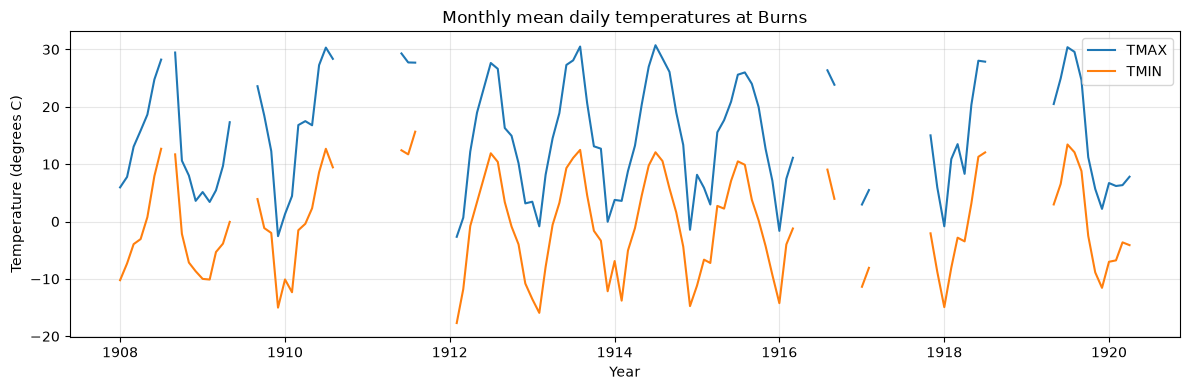

          PRCP     SNOW    SNWD     TMAX     TMIN     TOBS
count  1921.00  2044.00  807.00  2764.00  2714.00  2343.00
mean      2.03     4.40   56.70    14.82    -0.56     5.24
std       5.43    21.69   93.54    11.33     9.76    10.60
min       0.00     0.00    0.00   -21.70   -36.70   -32.20
25%       0.00     0.00    0.00     6.10    -6.70    -2.20
50%       0.00     0.00    0.00    15.60    -0.60     4.40
75%       0.50     0.00   76.00    25.00     7.20    13.90
max      61.00   305.00  533.00    37.20    26.10    30.60


In [109]:
#读取美国怀俄明州 Burns 气象站的数据，共 3231 条记录，时间为 1908 年 1 月 1 日至 1920 年 4 月 30 日。
weather = pd.read_csv("USC00481255.csv")
weather['DATE'] = pd.to_datetime(weather['DATE'])
print(weather.columns.tolist())
variables = ['PRCP', 'SNOW', 'SNWD', 'TMAX', 'TMIN', 'TOBS']
for name in variables:
    # 将这一列转换成数字
    weather[name] = pd.to_numeric(weather[name], errors='coerce')
    # 将缺测代码替换成缺失值
    weather[name] = weather[name].replace(-9999, float('nan'))
    # 读取这一列对应的质量说明
    attributes = weather[name + '_ATTRIBUTES'].fillna('')
    # 按逗号拆开，取第二项，也就是质量标记
    quality = attributes.str.split(',').str[1]
    quality = quality.fillna('').str.strip()
    # 质量标记不为空，表示未通过质量检查
    # 只删除有问题的数值，不删除整行其他有效数据
    weather.loc[quality != '', name] = float('nan')
    # 获取降水说明的第一项
rain_flag = weather['PRCP_ATTRIBUTES'].fillna('')
rain_flag = rain_flag.str.split(',').str[0]
# 不把“推定为零”的降水当作实际观测值
weather.loc[rain_flag == 'P', 'PRCP'] = float('nan')
# 换算单位
weather['PRCP'] = weather['PRCP'] / 10
weather['TMAX'] = weather['TMAX'] / 10
weather['TMIN'] = weather['TMIN'] / 10
weather['TOBS'] = weather['TOBS'] / 10
# 按日期排序
weather = weather.sort_values('DATE')
# 检查重复日期
print('重复日期数量：', weather['DATE'].duplicated().sum())
# 每个日期保留一行；这份文件实际没有重复日期
weather = weather.drop_duplicates(subset='DATE')
# 保留日期和六个气象变量
weather = weather[['DATE'] + variables].copy()
print('清理后的缺失值数量：')
print( weather.isna().sum())   
weather.head()

# 把日期设为索引
weather = data.set_index('DATE')
# 创建完整的连续日期
all_days = pd.date_range(weather.index.min(),weather.index.max())
print('原文件中没有记录的日期数：', len(all_days) - len(weather))
# 补齐缺失日期，数值保持为空
weather = weather.reindex(all_days)
# 提取最高气温和最低气温
temperature = weather[['TMAX', 'TMIN']]
# 按月计算平均值
monthly = temperature.resample('MS').mean()
# 统计每个月有多少天的有效气温数据
monthly_count = temperature.resample('MS').count()
# 这里约定：至少有15天有效记录，才显示该变量的月平均值
monthly = monthly.where(monthly_count >= 0)
plt.figure(figsize=(12, 4))
plt.plot(monthly.index, monthly['TMAX'], label='TMAX')
plt.plot(monthly.index, monthly['TMIN'], label='TMIN')
plt.xlabel('Year')
plt.ylabel('Temperature (degrees C)')
plt.title('Monthly mean daily temperatures at Burns')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 对六个气象变量进行描述性统计
statistics = weather[variables].describe()
# 保留两位小数
print(statistics.round(2))